# Bài 2 (Trang 15-17)


In [183]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

## 1. Nhập dữ liệu và thống kê thông tin cơ bản của các thuộc tính

In [184]:
print("Lê Quốc Trung - 6451071082")
df = pd.read_csv("titanic.csv")
print("Kích thước dữ liệu (dòng, cột):", df.shape)
df.head()

Lê Quốc Trung - 6451071082
Kích thước dữ liệu (dòng, cột): (1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [185]:
print("Lê Quốc Trung - 6451071082")
df.info()

Lê Quốc Trung - 6451071082
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   object 
 3   sex        1309 non-null   object 
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   object 
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    object 
 10  embarked   1307 non-null   object 
 11  boat       486 non-null    object 
 12  body       121 non-null    float64
 13  home.dest  745 non-null    object 
dtypes: float64(3), int64(4), object(7)
memory usage: 143.3+ KB


In [186]:
print("Lê Quốc Trung - 6451071082")
df.describe().T.round(2)

Lê Quốc Trung - 6451071082


,count,mean,std,min,25%,50%,75%,max
pclass,1309.0,2.29,0.84,1.00,2.0,3.00,3.00,3.00
survived,1309.0,0.38,0.49,0.00,0.0,0.00,1.00,1.00
age,1046.0,29.88,14.41,0.17,21.0,28.00,39.00,80.00
sibsp,1309.0,0.50,1.04,0.00,0.0,0.00,1.00,8.00
parch,1309.0,0.39,0.87,0.00,0.0,0.00,0.00,9.00
fare,1308.0,33.30,51.76,0.00,7.9,14.45,31.28,512.33
body,121.0,160.81,97.70,1.00,72.0,155.00,256.00,328.00


In [187]:
print("Lê Quốc Trung - 6451071082")
df.describe(include="object").T

Lê Quốc Trung - 6451071082


,count,unique,top,freq
name,1309,1307,"Kelly, Mr. James",2
sex,1309,2,male,843
ticket,1309,929,CA. 2343,11
cabin,295,186,C23 C25 C27,6
embarked,1307,3,S,914
boat,486,27,13,39
home.dest,745,369,"New York, NY",64


In [188]:
print("Lê Quốc Trung - 6451071082")
df.nunique().to_frame("so_gia_tri_khac_nhau")

Lê Quốc Trung - 6451071082


,so_gia_tri_khac_nhau
pclass,3
survived,2
name,1307
sex,2
age,98
sibsp,7
parch,8
ticket,929
fare,281
cabin,186


In [189]:
print("Lê Quốc Trung - 6451071082")
for col in ["survived", "pclass", "sex", "embarked", "sibsp", "parch"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index().to_string())
    print()
print("Tỉ lệ sống sót chung: {:.1%}".format(df["survived"].mean()))

Lê Quốc Trung - 6451071082
--- survived ---
survived
0    809
1    500

--- pclass ---
pclass
1    323
2    277
3    709

--- sex ---
sex
female    466
male      843

--- embarked ---
embarked
C      270
Q      123
S      914
NaN      2

--- sibsp ---
sibsp
0    891
1    319
2     42
3     20
4     22
5      6
8      9

--- parch ---
parch
0    1002
1     170
2     113
3       8
4       6
5       6
6       2
9       2

Tỉ lệ sống sót chung: 38.2%


**Mô tả thuộc tính:** `PassengerId` (mã), `Survived` (sống sót), `Pclass` (hạng vé 1/2/3), `Name` (họ tên),
`Sex` (giới tính), `Age` (tuổi), `SibSp` (số anh chị em/vợ chồng đi cùng), `Parch` (số cha mẹ/con cái đi cùng),
`Ticket` (số vé), `Fare` (giá vé), `Cabin` (số cabin), `Embarked` (cổng lên tàu: C = Cherbourg, Q = Queenstown, S = Southampton).

**Nhận xét nhanh:** chỉ 38,4% hành khách sống sót (dữ liệu hơi lệch về lớp tử vong). Tuổi trung bình khoảng 29,7, hơn một nửa
hành khách đi vé hạng 3, khoảng 65% là nam và đa số lên tàu ở cổng Southampton (S).

## 2. Danh sách 5 thuộc tính có nhiều giá trị rỗng nhất

In [190]:
print("Lê Quốc Trung - 6451071082")
missing = pd.DataFrame({
    "so_gia_tri_rong": df.isnull().sum(),
    "ti_le_%": (df.isnull().mean() * 100).round(2),
}).sort_values("so_gia_tri_rong", ascending=False)

top5_missing = missing.head(5)
top5_missing

Lê Quốc Trung - 6451071082


,so_gia_tri_rong,ti_le_%
body,1188,90.76
cabin,1014,77.46
boat,823,62.87
home.dest,564,43.09
age,263,20.09


Lê Quốc Trung - 6451071082


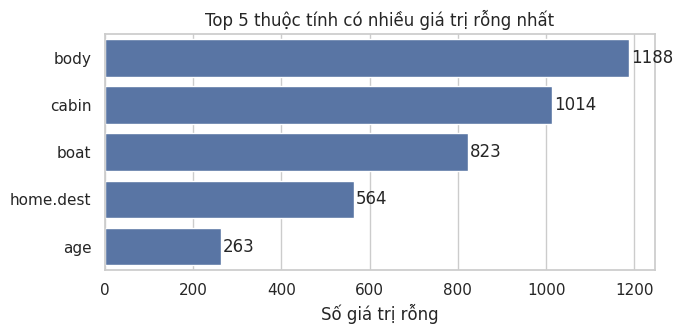

In [191]:
print("Lê Quốc Trung - 6451071082")
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=top5_missing["so_gia_tri_rong"], y=top5_missing.index, ax=ax, color="#4c72b0")
ax.set_title("Top 5 thuộc tính có nhiều giá trị rỗng nhất")
ax.set_xlabel("Số giá trị rỗng")
ax.set_ylabel("")
for i, v in enumerate(top5_missing["so_gia_tri_rong"]):
    ax.text(v + 5, i, str(v), va="center")
plt.tight_layout()
plt.show()

**Nhận xét:** chỉ có **3** thuộc tính bị thiếu dữ liệu, nên hai vị trí cuối của top 5 có số giá trị rỗng bằng 0.
- `Cabin`: thiếu 687/891 (77,1%), gần như không dùng được trực tiếp, nên sẽ bị loại bỏ ở bước 6.
- `Age`: thiếu 177/891 (19,9%), cần điền giá trị vì tuổi là thuộc tính quan trọng.
- `Embarked`: chỉ thiếu 2 dòng, có thể điền bằng giá trị xuất hiện nhiều nhất.

## 3. Quan hệ giữa Tuổi (Age), Giới tính (Sex) và khả năng sống sót (Survived)

Lê Quốc Trung - 6451071082


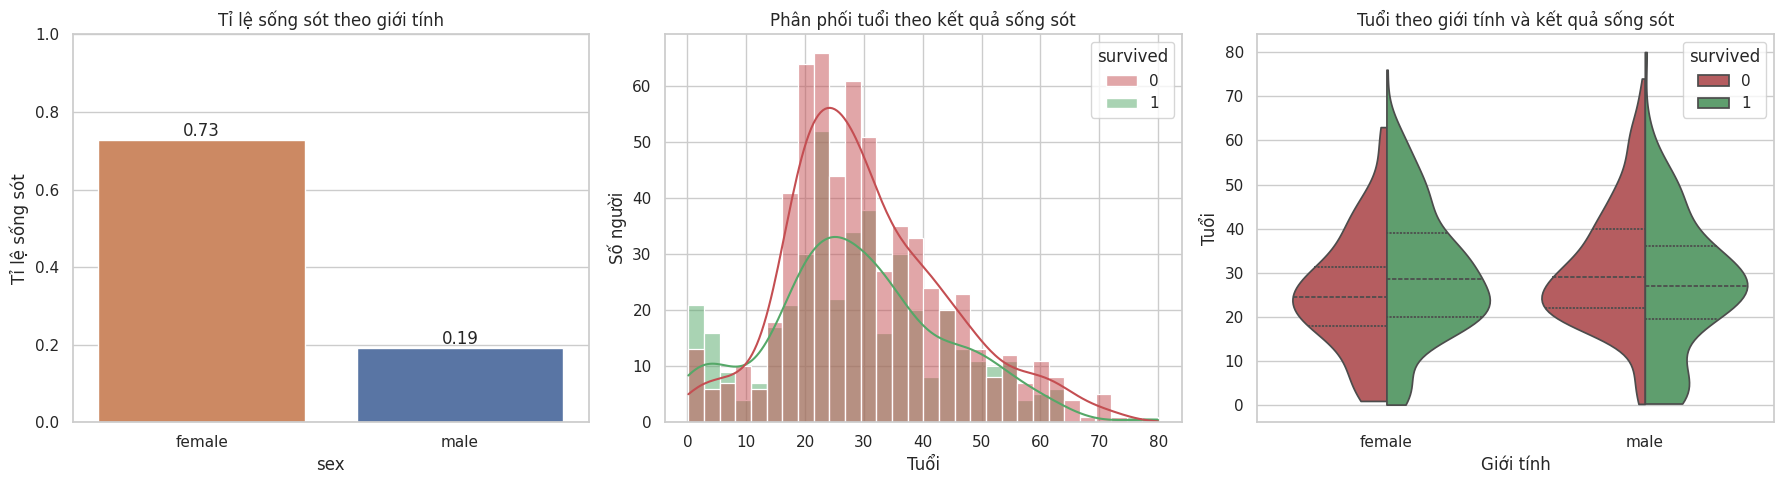

In [192]:
print("Lê Quốc Trung - 6451071082")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Tỉ lệ sống sót theo giới tính
sns.barplot(data=df, x="sex", y="survived", ax=axes[0], errorbar=None, palette=["#dd8452", "#4c72b0"],
            order=["female", "male"])
axes[0].set_title("Tỉ lệ sống sót theo giới tính")
axes[0].set_ylabel("Tỉ lệ sống sót")
axes[0].set_ylim(0, 1)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f")

# (b) Phân phối tuổi của người sống / tử vong
sns.histplot(data=df, x="age", hue="survived", bins=30, kde=True, multiple="layer", ax=axes[1],
             palette={0: "#c44e52", 1: "#55a868"})
axes[1].set_title("Phân phối tuổi theo kết quả sống sót")
axes[1].set_xlabel("Tuổi")
axes[1].set_ylabel("Số người")

# (c) Violin: tuổi theo giới tính, tách theo Survived
sns.violinplot(data=df, x="sex", y="age", hue="survived", split=True, inner="quart", cut=0, ax=axes[2],
               palette={0: "#c44e52", 1: "#55a868"}, order=["female", "male"])
axes[2].set_title("Tuổi theo giới tính và kết quả sống sót")
axes[2].set_xlabel("Giới tính")
axes[2].set_ylabel("Tuổi")

plt.tight_layout()
plt.show()

Lê Quốc Trung - 6451071082


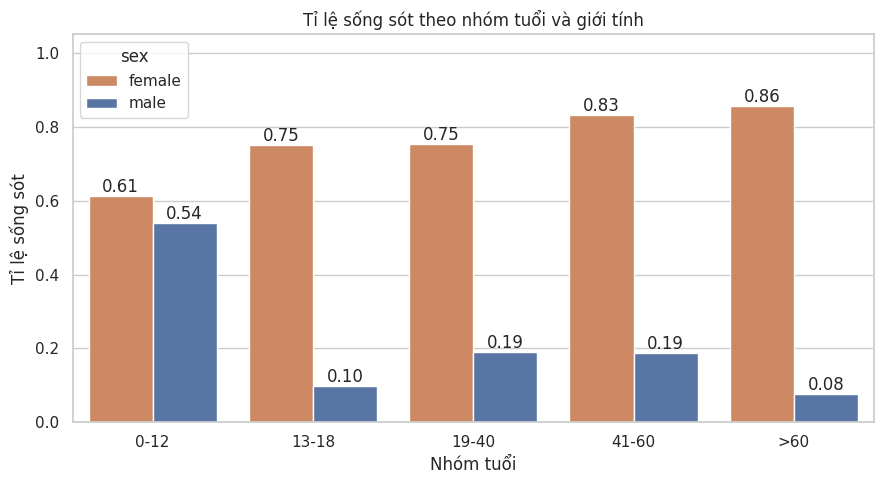

            mean         count     
sex       female   male female male
nhom_tuoi                          
0-12       0.614  0.540     44   50
13-18      0.750  0.098     48   51
19-40      0.752  0.191    218  408
41-60      0.831  0.187     71  123
>60        0.857  0.077      7   26


In [193]:
print("Lê Quốc Trung - 6451071082")
tmp = df.dropna(subset=["age"]).copy()
tmp["nhom_tuoi"] = pd.cut(tmp["age"], bins=[0, 12, 18, 40, 60, 100],
                          labels=["0-12", "13-18", "19-40", "41-60", ">60"])

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=tmp, x="nhom_tuoi", y="survived", hue="sex", errorbar=None, ax=ax,
            hue_order=["female", "male"], palette=["#dd8452", "#4c72b0"])
ax.set_title("Tỉ lệ sống sót theo nhóm tuổi và giới tính")
ax.set_xlabel("Nhóm tuổi")
ax.set_ylabel("Tỉ lệ sống sót")
ax.set_ylim(0, 1.05)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.tight_layout()
plt.show()

print(tmp.pivot_table(index="nhom_tuoi", columns="sex", values="survived", aggfunc=["mean", "count"], observed=True).round(3))

**Nhận xét:**
- **Giới tính ảnh hưởng rất mạnh:** nữ sống sót khoảng 74,2%, trong khi nam chỉ khoảng 18,9%. Điều này phù hợp với nguyên tắc ưu tiên "phụ nữ và trẻ em lên xuồng cứu sinh trước".
- **Độ tuổi có ảnh hưởng, nhưng yếu hơn giới tính và phụ thuộc giới tính:** trẻ em (dưới khoảng 12 tuổi) có tỉ lệ sống sót cao ở cả hai giới (nam ≈ 57%, nữ ≈ 59%). Sang nhóm 13-18 tuổi trở lên, tỉ lệ của nam rơi xuống chỉ còn khoảng 9-19%, còn nữ vẫn ở mức 75-79%.
- Biểu đồ phân phối cho thấy cột người tử vong cao hơn rõ ở nhóm thanh niên 20-35 tuổi (đa số là nam), còn nhóm dưới 10 tuổi có tỉ lệ sống sót cao hơn so với mặt bằng chung.
- Nhóm trên 60 tuổi rất ít người (nhất là nữ), nên các tỉ lệ cực đoan ở nhóm này (ví dụ nữ >60 đạt 100%) chưa đủ tin cậy.
- Kết luận: **Sex là yếu tố dự báo mạnh nhất**, Age là yếu tố bổ trợ (ưu thế của trẻ em).

## 4. Quan hệ giữa Cổng lên tàu (Embarked), Loại vé (Pclass) và Survived, phân biệt theo Sex

Lê Quốc Trung - 6451071082


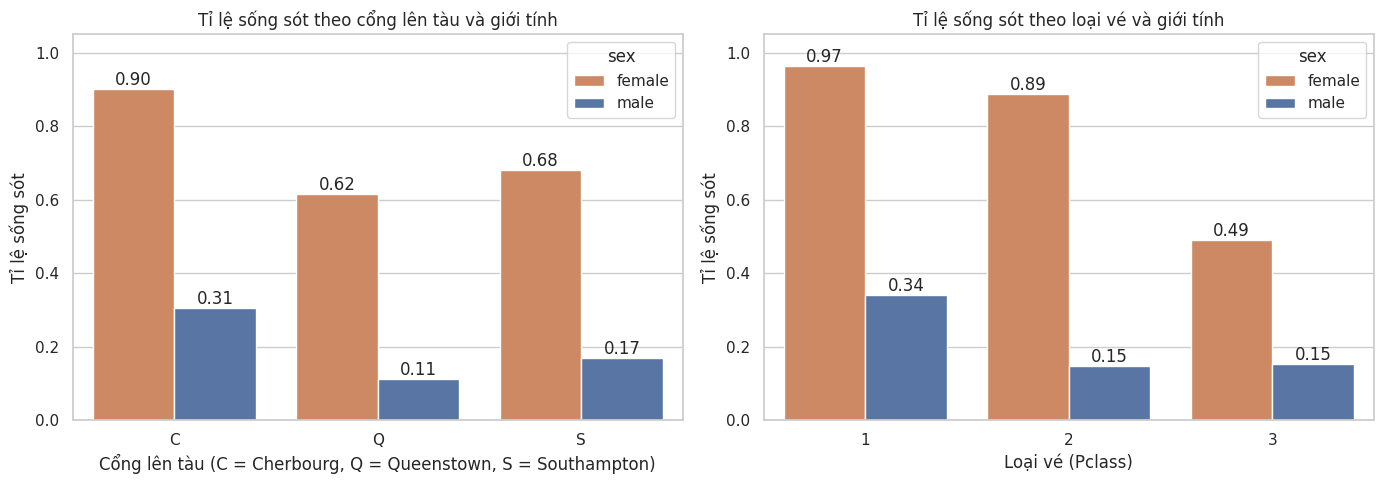

In [194]:
print("Lê Quốc Trung - 6451071082")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x="embarked", y="survived", hue="sex", order=["C", "Q", "S"],
            hue_order=["female", "male"], errorbar=None, ax=axes[0], palette=["#dd8452", "#4c72b0"])
axes[0].set_title("Tỉ lệ sống sót theo cổng lên tàu và giới tính")
axes[0].set_xlabel("Cổng lên tàu (C = Cherbourg, Q = Queenstown, S = Southampton)")
axes[0].set_ylabel("Tỉ lệ sống sót")
axes[0].set_ylim(0, 1.05)

sns.barplot(data=df, x="pclass", y="survived", hue="sex", hue_order=["female", "male"],
            errorbar=None, ax=axes[1], palette=["#dd8452", "#4c72b0"])
axes[1].set_title("Tỉ lệ sống sót theo loại vé và giới tính")
axes[1].set_xlabel("Loại vé (Pclass)")
axes[1].set_ylabel("Tỉ lệ sống sót")
axes[1].set_ylim(0, 1.05)

for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f")

plt.tight_layout()
plt.show()

Lê Quốc Trung - 6451071082


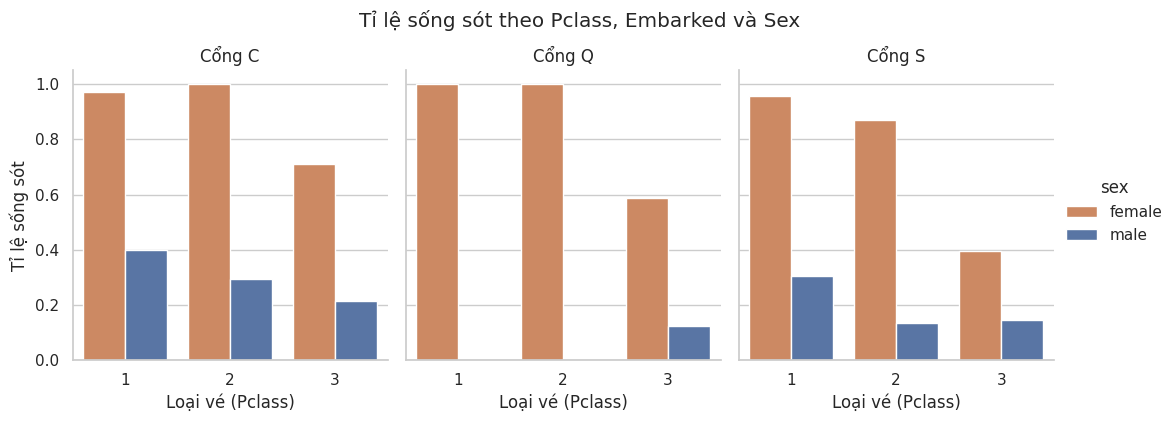

In [195]:
print("Lê Quốc Trung - 6451071082")
g = sns.catplot(data=df, x="pclass", y="survived", hue="sex", col="embarked", kind="bar",
                col_order=["C", "Q", "S"], hue_order=["female", "male"], errorbar=None,
                height=4, aspect=0.9, palette=["#dd8452", "#4c72b0"])
g.set_axis_labels("Loại vé (Pclass)", "Tỉ lệ sống sót")
g.set_titles("Cổng {col_name}")
g.fig.suptitle("Tỉ lệ sống sót theo Pclass, Embarked và Sex", y=1.05)
plt.show()

In [196]:
print("Lê Quốc Trung - 6451071082")
print((pd.crosstab(df["embarked"], df["pclass"], normalize="index") * 100).round(1))
print()
print("Số người theo (Embarked, Sex):")
print(pd.crosstab(df["embarked"], df["sex"]))
print()
print("Tỉ lệ sống sót theo (Pclass, Sex):")
print(df.pivot_table(index="pclass", columns="sex", values="survived", aggfunc="mean").round(3))
print()
print("Tỉ lệ sống sót theo (Embarked, Sex):")
print(df.pivot_table(index="embarked", columns="sex", values="survived", aggfunc="mean").round(3))

Lê Quốc Trung - 6451071082
pclass       1     2     3
embarked                  
C         52.2  10.4  37.4
Q          2.4   5.7  91.9
S         19.4  26.5  54.2

Số người theo (Embarked, Sex):
sex       female  male
embarked              
C            113   157
Q             60    63
S            291   623

Tỉ lệ sống sót theo (Pclass, Sex):
sex     female   male
pclass               
1        0.965  0.341
2        0.887  0.146
3        0.491  0.152

Tỉ lệ sống sót theo (Embarked, Sex):
sex       female   male
embarked               
C          0.903  0.306
Q          0.617  0.111
S          0.680  0.170


**Nhận xét:**
- **Loại vé:** vé hạng càng cao thì tỉ lệ sống sót càng lớn (hạng 1 ≈ 63%, hạng 2 ≈ 47%, hạng 3 ≈ 24%). Hạng 1 và 2 có cabin gần boong thuyền, được tiếp cận xuồng cứu sinh sớm hơn.
- **Loại vé kết hợp giới tính:** nữ hạng 1 và hạng 2 gần như sống sót hết (≈ 97% và 92%), nữ hạng 3 chỉ còn khoảng 50%. Nam giảm mạnh theo hạng (hạng 1 ≈ 37%, hạng 2 ≈ 16%, hạng 3 ≈ 14%). Như vậy giới tính vẫn là yếu tố chi phối, còn hạng vé quyết định mức chênh lệch bên trong từng giới.
- **Cổng lên tàu:** hành khách lên ở Cherbourg (C) có tỉ lệ sống sót cao nhất (≈ 55%), Queenstown (Q) khoảng 39%, Southampton (S) thấp nhất (≈ 34%). Ở cả hai giới, cổng C đều cao hơn cổng S (nữ ≈ 88% so với 69%, nam ≈ 31% so với 18%).
- **Giải thích:** bảng cơ cấu cho thấy cổng C có tỉ lệ vé hạng 1 cao hơn hẳn, còn cổng Q hầu như chỉ có vé hạng 3. Do đó sự khác biệt giữa các cổng phần lớn phản ánh khác biệt về hạng vé, không phải bản thân cổng lên tàu quyết định sự sống còn. Riêng số liệu nữ ở cổng Q (nhóm chủ yếu hạng 3, nhưng tỉ lệ sống sót vẫn 75%) và nam ở cổng Q (7%) cho thấy mẫu nhỏ nên dao động mạnh.

## 5. Số người đi cùng (SibSp, Parch) và quan hệ với Survived

In [197]:
print("Lê Quốc Trung - 6451071082")
df["SoNguoiDiCung"] = df["sibsp"] + df["parch"]

print("Số lượng theo SibSp (anh chị em / vợ chồng):")
print(df["sibsp"].value_counts().sort_index().to_string())
print("\nSố lượng theo Parch (cha mẹ / con cái):")
print(df["parch"].value_counts().sort_index().to_string())
print("\nSố lượng theo tổng số người đi cùng (SibSp + Parch):")
print(df["SoNguoiDiCung"].value_counts().sort_index().to_string())
print("\nSố hành khách đi một mình: {} ({:.1%})".format((df["SoNguoiDiCung"] == 0).sum(),
                                                          (df["SoNguoiDiCung"] == 0).mean()))

Lê Quốc Trung - 6451071082
Số lượng theo SibSp (anh chị em / vợ chồng):
sibsp
0    891
1    319
2     42
3     20
4     22
5      6
8      9

Số lượng theo Parch (cha mẹ / con cái):
parch
0    1002
1     170
2     113
3       8
4       6
5       6
6       2
9       2

Số lượng theo tổng số người đi cùng (SibSp + Parch):
SoNguoiDiCung
0     790
1     235
2     159
3      43
4      22
5      25
6      16
7       8
10     11

Số hành khách đi một mình: 790 (60.4%)


Lê Quốc Trung - 6451071082


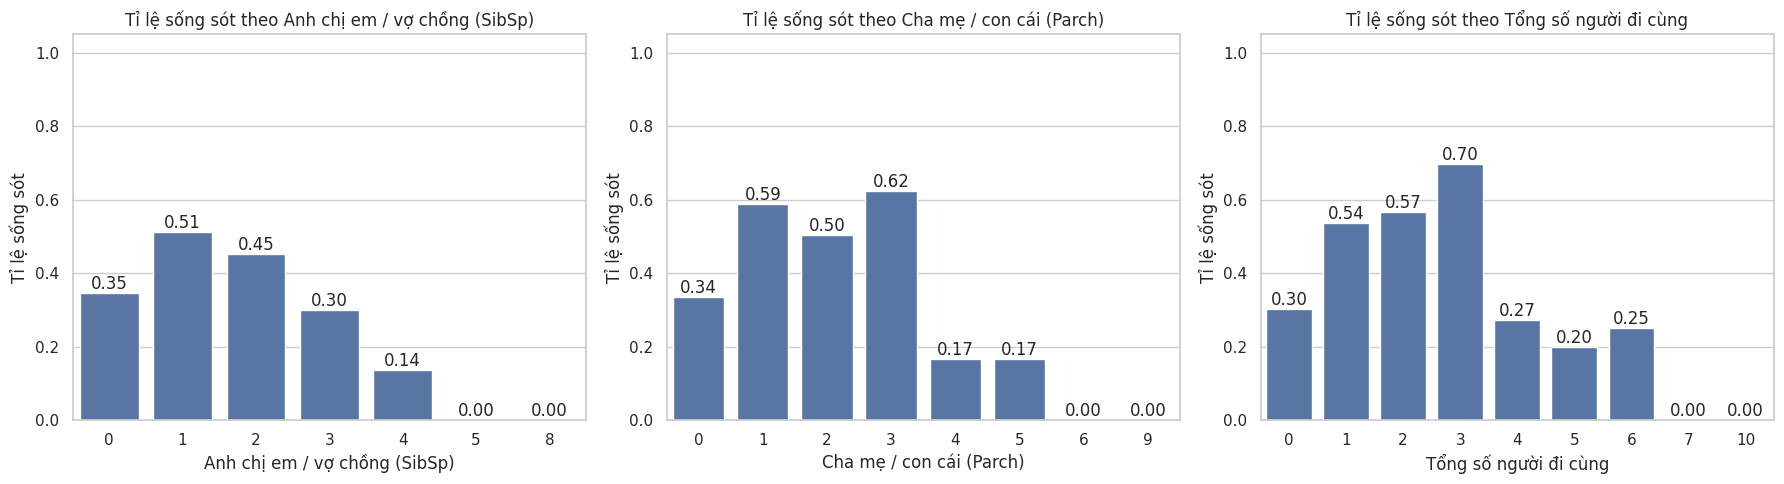

,so_nguoi,ti_le_song
SoNguoiDiCung,,
0,790,0.303
1,235,0.536
2,159,0.566
3,43,0.698
4,22,0.273
5,25,0.200
6,16,0.250
7,8,0.000
10,11,0.000


In [198]:
print("Lê Quốc Trung - 6451071082")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(axes,
                          ["sibsp", "parch", "SoNguoiDiCung"],
                          ["Anh chị em / vợ chồng (SibSp)", "Cha mẹ / con cái (Parch)", "Tổng số người đi cùng"]):
    sns.barplot(data=df, x=col, y="survived", errorbar=None, ax=ax, color="#4c72b0")
    ax.set_title("Tỉ lệ sống sót theo " + title)
    ax.set_xlabel(title)
    ax.set_ylabel("Tỉ lệ sống sót")
    ax.set_ylim(0, 1.05)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f")
plt.tight_layout()
plt.show()

summary = df.groupby("SoNguoiDiCung")["survived"].agg(so_nguoi="count", ti_le_song="mean").round(3)
summary

In [199]:
print("Lê Quốc Trung - 6451071082")
print(pd.crosstab(df["SoNguoiDiCung"], df["pclass"]))

Lê Quốc Trung - 6451071082
pclass           1    2    3
SoNguoiDiCung               
0              160  158  472
1              104   52   79
2               39   45   75
3                9   20   14
4                5    1   16
5                6    1   18
6                0    0   16
7                0    0    8
10               0    0   11


**Nhận xét:**
- Phần lớn hành khách **đi một mình** (537/891, 60,3%) và nhóm này có tỉ lệ sống sót thấp nhất trong nhóm đông (≈ 30%).
- Người đi cùng **1 đến 3** người thân có tỉ lệ sống sót cao hơn rõ rệt (≈ 55%, 58% và 72%), có thể nhờ được hỗ trợ lẫn nhau và được ưu tiên khi lên xuồng cùng người thân.
- Khi nhóm đi cùng **từ 4 người trở lên**, tỉ lệ giảm mạnh (≈ 20% khi đi cùng 4 người, ≈ 14% khi 5 người, và 0% khi 7 hoặc 10 người). Bảng chéo với `Pclass` cho thấy các gia đình đông đa số mua vé hạng 3, vốn đã có tỉ lệ sống sót thấp. Ngoài ra gia đình đông khó di chuyển cùng nhau để lên xuồng.
- Kết luận: số người đi cùng có quan hệ **phi tuyến** với khả năng sống sót, đi một mình hoặc đi nhóm quá đông đều bất lợi, đi cùng nhóm nhỏ (1-3 người) thuận lợi nhất. Cỡ mẫu các nhóm lớn rất nhỏ (6-29 người), nên cần thận trọng khi kết luận.

## 6. Tiền xử lý thuộc tính thiếu dữ liệu và xóa thuộc tính không cần thiết

Quyết định xử lý:
- `Age` (thiếu 177): điền bằng **trung vị tuổi của nhóm cùng (Sex, Pclass)**, tốt hơn dùng một giá trị chung vì tuổi khác nhau giữa các hạng vé và giới tính.
- `Embarked` (thiếu 2): điền bằng **giá trị xuất hiện nhiều nhất (mode)**.
- `Cabin` (thiếu 77%): **xóa**.
- `PassengerId` (chỉ là mã định danh), `Ticket` (số vé, gần như duy nhất cho từng nhóm, ít giá trị dự báo): **xóa**.
- `Name` tạm giữ lại để trích xuất danh hiệu ở bước 7, sau đó sẽ xóa.

In [200]:
print("Lê Quốc Trung - 6451071082")
data = df.drop(columns=["SoNguoiDiCung"]).copy()
# Điền Age theo trung vị của nhóm (Sex, Pclass)
data["Age"] = data.groupby(["sex", "pclass"])["age"].transform(lambda s: s.fillna(s.median()))

# Điền Embarked bằng mode
mode_embarked = data["embarked"].mode()[0]
print("Giá trị Embarked phổ biến nhất:", mode_embarked)
data["embarked"] = data["embarked"].fillna(mode_embarked)

# Xóa các thuộc tính không cần thiết
data = data.drop(columns=["cabin", "ticket"])

print("\nSố giá trị rỗng sau xử lý:")
print(data.isnull().sum().to_string())
print("\nCác cột còn lại:", list(data.columns))

Lê Quốc Trung - 6451071082
Giá trị Embarked phổ biến nhất: S

Số giá trị rỗng sau xử lý:
pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
fare            1
embarked        0
boat          823
body         1188
home.dest     564
Age             0

Các cột còn lại: ['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'boat', 'body', 'home.dest', 'Age']


## 7. Biến đổi thuộc tính

### 7.1 Chuyển đổi giá vé (Fare) về kiểu nguyên
Giữ lại bản gốc `Fare_goc` (số thực) để chia nhóm giá vé chính xác theo các ngưỡng gợi ý (7.91, 14.454, ...) và để tính giá vé trên mỗi người ở bước 8.

In [201]:
print("Lê Quốc Trung - 6451071082")

data["fare_goc"] = data["fare"].fillna(
    data.groupby("pclass")["fare"].transform("median")
)
data["fare_goc"] = data["fare_goc"].fillna(data["fare"].median())
data["fare"] = data["fare_goc"].astype(int)  # bỏ phần thập phân

print(data["fare"].dtype)
data[["fare_goc", "fare"]].head()

Lê Quốc Trung - 6451071082
int64


,fare_goc,fare
0,211.3375,211
1,151.5500,151
2,151.5500,151
3,151.5500,151
4,151.5500,151


### 7.2 Trích xuất danh hiệu (Title) từ tên
Tên có dạng `Họ, Danh hiệu. Tên`. Ta lấy phần danh hiệu, sau đó gộp các danh hiệu hiếm.

In [202]:
print("Lê Quốc Trung - 6451071082")
data["title"] = data["name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
print("Các danh hiệu gốc:")
print(data["title"].value_counts().to_string())

Lê Quốc Trung - 6451071082
Các danh hiệu gốc:
title
Mr              757
Miss            260
Mrs             197
Master           61
Dr                8
Rev               8
Col               4
Major             2
Mlle              2
Ms                2
Lady              1
Capt              1
Mme               1
Sir               1
Jonkheer          1
Dona              1
Don               1
the Countess      1


In [203]:
print("Lê Quốc Trung - 6451071082")
title_map = {
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Rare", "the Countess": "Rare", "Countess": "Rare", "Sir": "Rare", "Don": "Rare", "Dona": "Rare",
    "Jonkheer": "Rare", "Capt": "Rare", "Col": "Rare", "Major": "Rare", "Dr": "Rare", "Rev": "Rare",
}
data["title"] = data["title"].replace(title_map)

print(data["title"].value_counts().to_string())
print()
print(data.groupby("title")["survived"].agg(so_nguoi="count", ti_le_song="mean").round(3))

Lê Quốc Trung - 6451071082
title
Mr        757
Miss      264
Mrs       198
Master     61
Rare       29

        so_nguoi  ti_le_song
title                       
Master        61       0.508
Miss         264       0.678
Mr           757       0.162
Mrs          198       0.788
Rare          29       0.379


**Nhận xét:** `Title` chứa cả thông tin giới tính, tình trạng hôn nhân và tuổi. `Master` (bé trai) có tỉ lệ sống sót ≈ 57,5%, `Miss` ≈ 70%, `Mrs` ≈ 79%, còn `Mr` chỉ ≈ 16%. Đây là thuộc tính rất hữu ích cho mô hình dự đoán.

7.3 Chuyển giới tính (Sex) và cổng lên tàu (Embarked) thành số

In [204]:
print("Lê Quốc Trung - 6451071082")

# Dùng replace thay vì map: nếu cột đã là số thì giữ nguyên, không bị NaN
data["sex"] = data["sex"].replace({"male": 0, "female": 1}).astype(int)
data["embarked"] = data["embarked"].replace({"S": 0, "C": 1, "Q": 2}).astype(int)

# Mã hóa Title thành số; danh hiệu lạ nào không có trong từ điển sẽ được xếp vào nhóm Rare (5)
title_num = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
data["title_num"] = data["title"].map(title_num).fillna(5).astype(int)

data[["sex", "embarked", "title", "title_num"]].head()

Lê Quốc Trung - 6451071082


,sex,embarked,title,title_num
0,1,0,Miss,2
1,0,0,Master,4
2,1,0,Miss,2
3,0,0,Mr,1
4,1,0,Mrs,3


*văn bản in nghiêng*### 7.4 Chia tuổi (Age) thành 8 nhóm
Dùng đúng các mốc gợi ý: ≤11, 11-18, :18-22, 22-27, 27-33, 33-40, 40-66, >66

1.   Mục danh sách
2.   Mục danh sách

(khoảng bên phải đóng).

In [205]:
print("Lê Quốc Trung - 6451071082")

# Điền tuổi thiếu bằng trung vị của nhóm (sex, pclass)
data["age"] = data.groupby(["sex", "pclass"])["age"].transform(lambda s: s.fillna(s.median()))

# Phòng trường hợp còn sót (nhóm không có tuổi nào): điền bằng trung vị chung
data["age"] = data["age"].fillna(data["age"].median())

# Điền embarked thiếu bằng giá trị phổ biến nhất (nếu cột còn là chữ S/C/Q hoặc đã là số đều được)
data["embarked"] = data["embarked"].fillna(data["embarked"].mode()[0])

print("Số giá trị rỗng còn lại:", data[["age", "embarked"]].isnull().sum().to_dict())

Lê Quốc Trung - 6451071082
Số giá trị rỗng còn lại: {'age': 0, 'embarked': 0}


Lê Quốc Trung - 6451071082


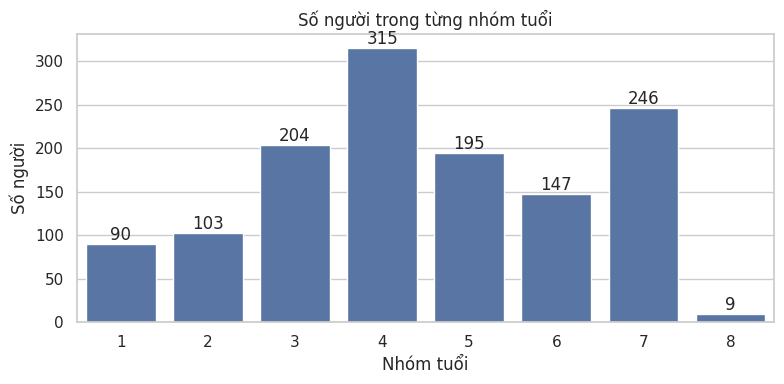

In [206]:
print("Lê Quốc Trung - 6451071082")

# Điền tuổi thiếu trước khi chia nhóm
data["age"] = data["age"].fillna(data["age"].median())

age_bins = [-np.inf, 11, 18, 22, 27, 33, 40, 66, np.inf]
data["age_group"] = pd.cut(
    data["age"],
    bins=age_bins,
    labels=range(1, 9)
).astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=data, x="age_group", ax=ax, color="#4c72b0")
ax.set_title("Số người trong từng nhóm tuổi")
ax.set_xlabel("Nhóm tuổi")
ax.set_ylabel("Số người")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

**Nhận xét:** các nhóm 3, 5, 6, 7 khá đều nhau (khoảng 130-145 người), nhóm 1 và 2 có khoảng 70 người, còn nhóm 8 (trên 66 tuổi) chỉ có 7 người nên không thể cân bằng tuyệt đối. Nhóm 4 (23-27 tuổi) đông nhất (200 người) vì 177 tuổi bị thiếu được điền bằng trung vị theo nhóm (khoảng 25-30 tuổi) nên dồn vào khoảng này. Nếu cần các nhóm thật sự cân bằng, có thể dùng `pd.qcut(data["Age"], 8)`, nhưng khi đó các mốc sẽ khác với gợi ý của đề.

### 7.5 Chia giá vé (Fare) thành 6 nhóm
Các mốc gợi ý: ≤7.91, 7.91-14.454, 14.454-31, 31-99, 99-250, >250. Chia theo giá vé gốc (số thực) để khớp ngưỡng.

In [207]:
print("Lê Quốc Trung - 6451071082")

data.columns = data.columns.str.strip().str.lower()

# Nếu chưa có fare_goc, tạo từ fare
if "fare_goc" not in data.columns:
    data["fare_goc"] = data["fare"]

data["fare_goc"] = pd.to_numeric(data["fare_goc"], errors="coerce")

# Điền fare thiếu bằng trung vị theo pclass, rồi dùng trung vị toàn cột nếu còn thiếu
data["fare_goc"] = data["fare_goc"].fillna(
    data.groupby("pclass")["fare_goc"].transform("median")
)
data["fare_goc"] = data["fare_goc"].fillna(data["fare_goc"].median())

fare_bins = [-np.inf, 7.91, 14.454, 31, 99, 250, np.inf]
data["fare_group"] = pd.cut(
    data["fare_goc"], bins=fare_bins, labels=range(1, 7)
).astype(int)

fare_summary = data.groupby("fare_group").agg(
    so_nguoi=("fare_goc", "count"),
    fare_min=("fare_goc", "min"),
    fare_max=("fare_goc", "max"),
    ti_le_song=("survived", "mean")
).round(3)

fare_summary

Lê Quốc Trung - 6451071082


,so_nguoi,fare_min,fare_max,ti_le_song
fare_group,,,,
1,337,0.000,7.896,0.228
2,311,7.925,14.400,0.289
3,331,14.454,31.000,0.435
4,246,31.275,93.500,0.524
5,67,106.425,247.521,0.687
6,17,262.375,512.329,0.824


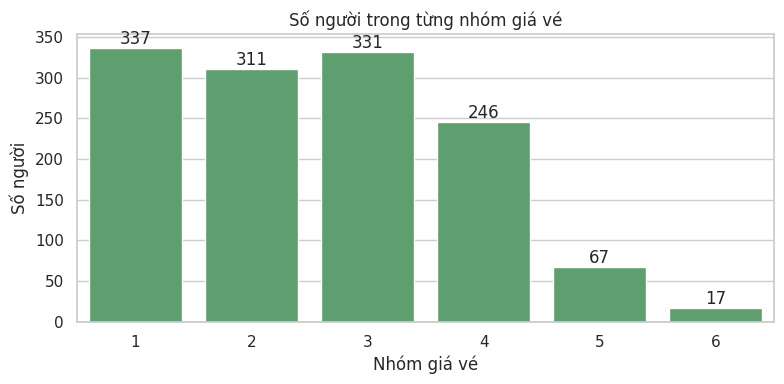

In [208]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=data, x="fare_group", ax=ax, color="#55a868")
ax.set_title("Số người trong từng nhóm giá vé")
ax.set_xlabel("Nhóm giá vé")
ax.set_ylabel("Số người")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

**Nhận xét:** bốn nhóm giá vé đầu khá cân bằng (khoảng 160-250 người mỗi nhóm), còn hai nhóm giá cao nhất (99-250 và trên 250) ít người do chỉ một số hành khách hạng 1 mua vé đắt. Tỉ lệ sống sót tăng dần theo nhóm giá vé, phù hợp với kết quả theo hạng vé ở bước 4.

## 8. Tạo các thuộc tính mới

- **Age_class** = Age × Pclass.
- **Fare_per_person** = giá vé / (số người đi cùng + 1), làm tròn về số nguyên. Số người đi cùng = SibSp + Parch; cộng 1 để tính cả chính hành khách đó (đồng thời tránh chia cho 0 với người đi một mình).

In [209]:
print("Lê Quốc Trung - 6451071082")

data.columns = data.columns.str.strip().str.lower()

# Bỏ các cột trùng tên sau khi chuẩn hóa chữ hoa/thường
duplicate_columns = data.columns[data.columns.duplicated()].tolist()
print("Cột trùng được bỏ:", duplicate_columns)
data = data.loc[:, ~data.columns.duplicated()].copy()

# Đặt lại chỉ mục để tránh lỗi căn chỉnh dữ liệu
data = data.reset_index(drop=True)

for col in ["age", "pclass", "sibsp", "parch"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data["age"] = data["age"].fillna(data["age"].median())

if "fare_goc" not in data.columns:
    data["fare_goc"] = data["fare"]

data["fare_goc"] = pd.to_numeric(data["fare_goc"], errors="coerce")
data["fare_goc"] = data["fare_goc"].fillna(
    data.groupby("pclass")["fare_goc"].transform("median")
)
data["fare_goc"] = data["fare_goc"].fillna(data["fare_goc"].median())

data["age_class"] = data["age"] * data["pclass"]
data["so_nguoi_di_cung"] = data["sibsp"] + data["parch"]
data["fare_per_person"] = (
    data["fare_goc"] / (data["so_nguoi_di_cung"] + 1)
).round().astype(int)

data[
    ["age", "pclass", "age_class", "fare_goc", "sibsp", "parch",
     "so_nguoi_di_cung", "fare_per_person"]
].head(10)

Lê Quốc Trung - 6451071082
Cột trùng được bỏ: ['age']


,age,pclass,age_class,fare_goc,sibsp,parch,so_nguoi_di_cung,fare_per_person
0,29.0000,1,29.0000,211.3375,0,0,0,211
1,0.9167,1,0.9167,151.5500,1,2,3,38
2,2.0000,1,2.0000,151.5500,1,2,3,38
3,30.0000,1,30.0000,151.5500,1,2,3,38
4,25.0000,1,25.0000,151.5500,1,2,3,38
5,48.0000,1,48.0000,26.5500,0,0,0,27
6,63.0000,1,63.0000,77.9583,1,0,1,39
7,39.0000,1,39.0000,0.0000,0,0,0,0
8,53.0000,1,53.0000,51.4792,2,0,2,17
9,71.0000,1,71.0000,49.5042,0,0,0,50


In [210]:
print("Lê Quốc Trung - 6451071082")

data.columns = data.columns.str.strip().str.lower()
data = data.drop(columns=["name", "fare_goc"], errors="ignore")

print("Số giá trị rỗng:", int(data.isnull().sum().sum()))
data.info()

Lê Quốc Trung - 6451071082
Số giá trị rỗng: 2575
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   pclass            1309 non-null   int64  
 1   survived          1309 non-null   int64  
 2   sex               1309 non-null   int64  
 3   age               1309 non-null   float64
 4   sibsp             1309 non-null   int64  
 5   parch             1309 non-null   int64  
 6   fare              1309 non-null   int64  
 7   embarked          1309 non-null   int64  
 8   boat              486 non-null    object 
 9   body              121 non-null    float64
 10  home.dest         745 non-null    object 
 11  title             1309 non-null   object 
 12  title_num         1309 non-null   int64  
 13  age_group         1309 non-null   int64  
 14  fare_group        1309 non-null   int64  
 15  age_class         1309 non-null   float6

In [211]:
print("Lê Quốc Trung - 6451071082")
data.head(10)

Lê Quốc Trung - 6451071082


,pclass,survived,sex,age,sibsp,parch,fare,embarked,boat,body,home.dest,title,title_num,age_group,fare_group,age_class,so_nguoi_di_cung,fare_per_person
0,1,1,1,29.0000,0,0,211,0,2,NaN,"St Louis, MO",Miss,2,5,5,29.0000,0,211
1,1,1,0,0.9167,1,2,151,0,11,NaN,"Montreal, PQ / Chesterville, ON",Master,4,1,5,0.9167,3,38
2,1,0,1,2.0000,1,2,151,0,NaN,NaN,"Montreal, PQ / Chesterville, ON",Miss,2,1,5,2.0000,3,38
3,1,0,0,30.0000,1,2,151,0,NaN,135.0,"Montreal, PQ / Chesterville, ON",Mr,1,5,5,30.0000,3,38
4,1,0,1,25.0000,1,2,151,0,NaN,NaN,"Montreal, PQ / Chesterville, ON",Mrs,3,4,5,25.0000,3,38
5,1,1,0,48.0000,0,0,26,0,3,NaN,"New York, NY",Mr,1,7,3,48.0000,0,27
6,1,1,1,63.0000,1,0,77,0,10,NaN,"Hudson, NY",Miss,2,7,4,63.0000,1,39
7,1,0,0,39.0000,0,0,0,0,NaN,NaN,"Belfast, NI",Mr,1,6,1,39.0000,0,0
8,1,1,1,53.0000,2,0,51,0,D,NaN,"Bayside, Queens, NY",Mrs,3,7,4,53.0000,2,17
9,1,0,0,71.0000,0,0,49,1,NaN,22.0,"Montevideo, Uruguay",Mr,1,8,4,71.0000,0,50


Lê Quốc Trung - 6451071082


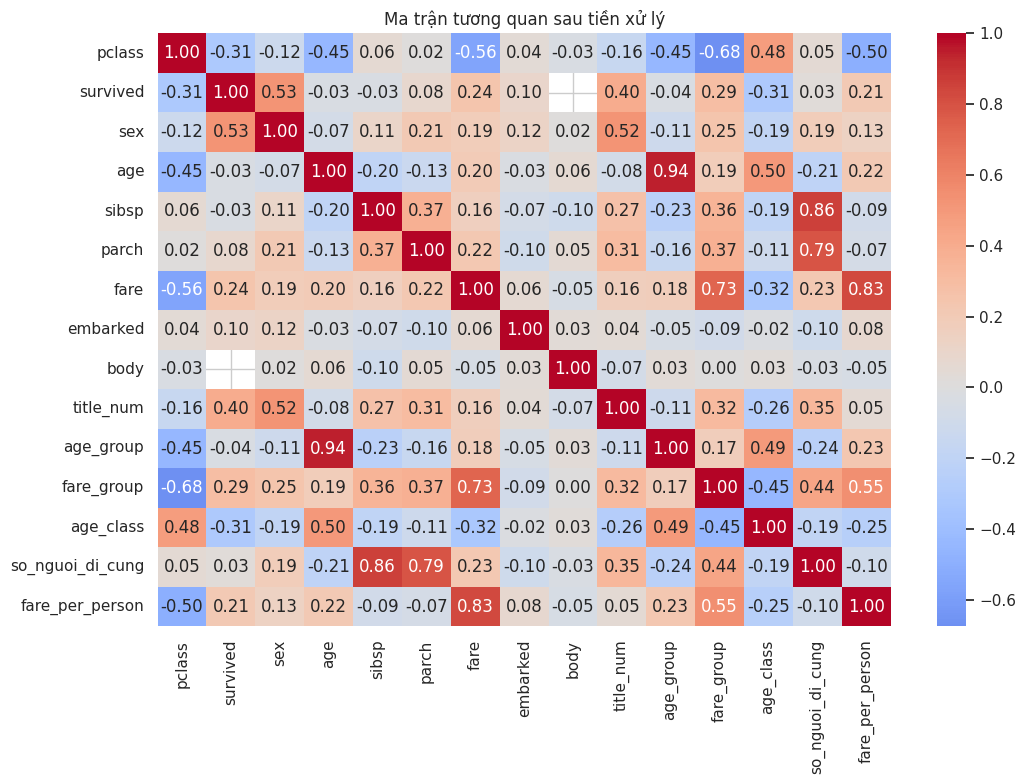

,tuong_quan_voi_Survived
sex,0.529
title_num,0.403
pclass,-0.312
age_class,-0.306
fare_group,0.287
fare,0.245
fare_per_person,0.211
embarked,0.098
parch,0.083
age_group,-0.039


In [212]:
print("Lê Quốc Trung - 6451071082")
corr = data.drop(columns=["title"]).corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Ma trận tương quan sau tiền xử lý")
plt.tight_layout()
plt.show()

corr["survived"].drop("survived").sort_values(key=abs, ascending=False).round(3).to_frame("tuong_quan_voi_Survived")

In [213]:
print("Lê Quốc Trung - 6451071082")
data.to_csv("titanic_clean.csv", index=False)
print("Đã lưu titanic_clean.csv:", data.shape)

Lê Quốc Trung - 6451071082
Đã lưu titanic_clean.csv: (1309, 18)


## Tổng kết

1. Dữ liệu 891 hành khách, chỉ 38,4% sống sót; 3 thuộc tính thiếu dữ liệu (`Cabin`, `Age`, `Embarked`).
2. **Giới tính** và **hạng vé** là hai yếu tố ảnh hưởng mạnh nhất tới khả năng sống sót; tuổi (ưu thế của trẻ em) và số người đi cùng (nhóm nhỏ 1-3 người có lợi) là các yếu tố bổ trợ; cổng lên tàu chủ yếu phản ánh cơ cấu hạng vé.
3. Sau tiền xử lý, dữ liệu không còn giá trị rỗng, các thuộc tính phân loại đã mã hóa thành số, và có thêm các thuộc tính mới (`Title`, `Age_group`, `Fare_group`, `Age_class`, `Fare_per_person`) sẵn sàng cho bước xây dựng mô hình.